#Classificando as espécies da flor Iris utilizando Keras / MLP


##Etapa 01
Importar as bibliotecas de computação científica e aprendizado de máquina.

In [14]:
#Bibliotecas de aprendizado de máquina
from sklearn import datasets
from sklearn.model_selection import train_test_split
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

#Bibliotecas de computação científica
import numpy as np
import math
import matplotlib.pyplot as plt


##Etapa 02
Importar a base de dados Iris do sklearn e definir as classes.

In [15]:
iris_dataset = datasets.load_iris()
#print("Descrição da base de dados :: ", iris_dataset['DESCR'])


##Etapa 03
Conhecer a base de dados e plotar as características comprimento e largura de pétala para as 3 classes.


Quantidade de labels:  (150,)
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]

Nome das classes:  ['setosa' 'versicolor' 'virginica']

Nome das características:  ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


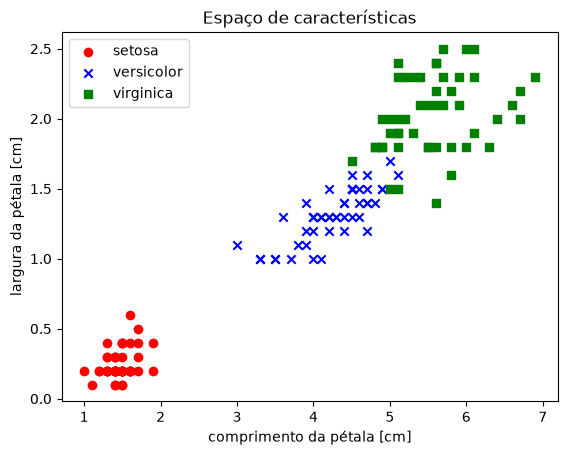

In [16]:
print('\nQuantidade de labels: ', iris_dataset.target.shape)
print(iris_dataset.target)

print('\nNome das classes: ', iris_dataset.target_names)

print('\nNome das características: ', iris_dataset.feature_names)

#Selecionar as características comprimento e largura de pétala
data_plot = iris_dataset.data[0:150,[2, 3]]

#Plotar os dados
plt.scatter(data_plot[:50, 0], data_plot[:50, 1],
            color='red', marker='o', label='setosa')

plt.scatter(data_plot[50:100, 0], data_plot[50:100, 1],
            color='blue', marker='x', label='versicolor')

plt.scatter(data_plot[100:150, 0], data_plot[100:150, 1],
            color='green', marker='s', label='virginica')
plt.title('Espaço de características')
plt.xlabel('comprimento da pétala [cm]')
plt.ylabel('largura da pétala [cm]')
plt.legend(loc='upper left')

plt.show()


##Etapa 04
Partição dos dados: 80% treinamento e 20% validação.

In [17]:
#Obter os dados
X = iris_dataset.data
Y = iris_dataset.target

#Particionar os dados
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.20, stratify=Y, random_state=42)

print('x_train', x_train.shape)
print('y_train', y_train.shape)
print('x_test', x_test.shape)
print('y_test', y_test.shape)
print(y_test)


x_train (120, 4)
y_train (120,)
x_test (30, 4)
y_test (30,)
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


##Etapa 05
Construir a rede neural (MLP) utilizando o Keras.

In [18]:
keras.backend.clear_session()
model = Sequential()
model.add(Dense(20, input_dim = 4, activation='relu'))
model.add(Dense(3, activation='softmax'))

model.summary()


c:\Users\leonardo.flores\Desktop\UFOP\CDD109 - REDES NEURAIS ARTIFICIAIS E DEEP LEARNING\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 20)             │           100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 163 (652.00 B)

 Trainable params: 163 (652.00 B)

 Non-trainable params: 0 (0.00 B)

##Etapa 06
Compilar o modelo.

Optimizer: As opções são encontradas em https://keras.io/api/optimizers/

Loss: As opções são encontradas em https://keras.io/api/losses/

Metrics: As opções são encontradas em https://keras.io/api/metrics/


In [19]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_accuracy'])


##Etapa 07
Treinar o modelo e realizar a validação.

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 3.0522 - sparse_categorical_accuracy: 0.3333 - val_loss: 2.6703 - val_sparse_categorical_accuracy: 0.3333
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.3866 - sparse_categorical_accuracy: 0.3333 - val_loss: 2.1393 - val_sparse_categorical_accuracy: 0.3333
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.9325 - sparse_categorical_accuracy: 0.3333 - val_loss: 1.7168 - val_sparse_categorical_accuracy: 0.3000
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.5373 - sparse_categorical_accuracy: 0.3417 - val_loss: 1.3863 - val_sparse_categorical_accuracy: 0.3000
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.2398 - sparse_categorical_accuracy: 0.4333 - val_loss: 1.1073 - val_sparse_categorical_accuracy: 0.5667
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9858 - sparse_categorical_accuracy: 0.5750 - val_loss: 0.9157 - val_sparse_categorical_accuracy: 0.6667
Epoch 7/1

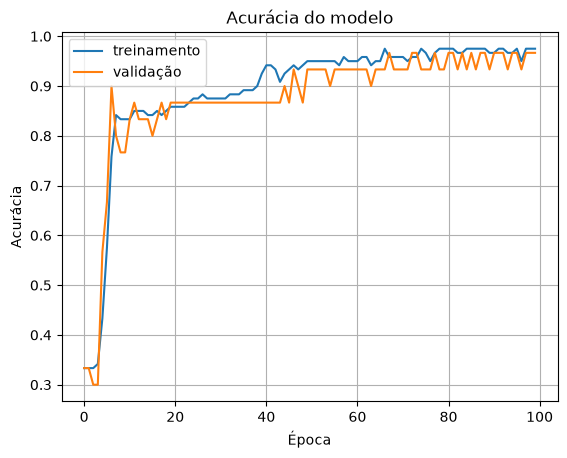

In [20]:
history = model.fit(x_train, y_train, epochs=100, batch_size=10, validation_data=(x_test, y_test))
plt.plot(history.history['sparse_categorical_accuracy'])
plt.plot(history.history['val_sparse_categorical_accuracy'])
plt.title('Acurácia do modelo')
plt.ylabel('Acurácia')
plt.xlabel('Época')
plt.legend(['treinamento', 'validação'], loc='upper left')
plt.grid()
plt.show()


##Etapa 08
Avaliando o modelo.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step


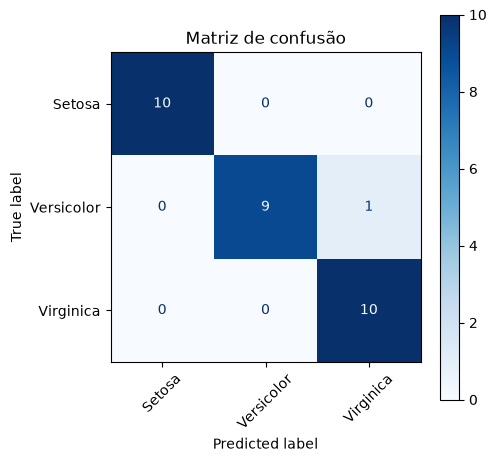

              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      0.90      0.95        10
   Virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [21]:
y_pred_prob = model.predict(x_test)

# Converte as probabilidades em classes discretas (0, 1 ou 2)
y_pred = np.argmax(y_pred_prob, axis=1)

# Matriz de confusao (linhas = classe real, colunas = classe prevista)
nomes_flores = ['Setosa', 'Versicolor', 'Virginica']

cm = confusion_matrix(y_test, y_pred, labels=range(3))

fig, ax = plt.subplots(figsize=(5, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=nomes_flores)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45)
plt.title('Matriz de confusão')
plt.show()

# Precisao, recall e F1 por classe
print(classification_report(y_test, y_pred, labels=range(3),
                            target_names=nomes_flores, zero_division=0))


## Métricas

As métricas apresentadas avaliam o desempenho do classificador:

- **Precision (Precisão):** indica, entre as amostras classificadas como pertencentes a uma determinada classe, quantas realmente pertencem a ela. Uma precisão alta significa poucos falsos positivos.
- **Recall (Revocação):** indica a proporção de amostras de uma classe que foi corretamente identificada pelo modelo. Um recall alto significa poucos falsos negativos.
- **F1-score:** é a média harmônica entre precision e recall, combinando as duas métricas em um único valor. É útil quando se deseja equilibrar a identificação correta das classes e evitar falsos positivos.
- **Support:** representa o número de amostras reais de cada classe utilizadas na avaliação.

Métricas gerais:
- **Accuracy (Acurácia):** proporção total de amostras classificadas corretamente.
- **Macro avg:** calcula a média das métricas entre as classes, atribuindo o mesmo peso a cada uma, independentemente da quantidade de amostras.
- **Weighted avg:** calcula a média ponderada pelo número de amostras (support) de cada classe.
